<nav class="navbar navbar-default">
  <div class="container-fluid">
    <div class="navbar-header">
      <a class="navbar-brand" href="_Oving5.ipynb">Øving 5</a>
    </div>
    <ul class="nav navbar-nav">
      <li><a href="Generelt%20om%20lister.ipynb">Generelt om lister</a></li>
      <li><a href="Lett%20og%20blandet.ipynb">Lett og blandet</a></li>
      <li class="active"><a href="Intro%20til%20numpy-arrays.ipynb">Intro til numpy-arrays</a></li>
      <li><a href="Kodeforstaelse.ipynb">Kodeforståelse</a></li>
      <li><a href="Vektorer.ipynb">Vektorer</a></li>
      <li><a href="Lister%20og%20lokker.ipynb">Lister og løkker</a></li>
      <li><a href="Teoridelen%20paa%20eksamen.ipynb">Teoridelen på eksamen</a></li>
      <li><a href="Gangetabell%20og%20lister.ipynb">Gangetabell og lister</a></li>
      <li><a href="Lotto.ipynb">Lotto</a></li>
      <li><a href="Tannfeen.ipynb">Tannfeen</a></li>
      <li><a href="Chattebot.ipynb">Chattebot</a></li>
      <li><a href="Matriseaddisjon.ipynb">Matriseaddisjon</a></li>
      <li><a href="Temperaturanalyse.ipynb">Temperaturanalyse</a></li>
    </ul>
  </div>
</nav>

# Temperaturanalyse

**Læringsmål:**

* Funksjoner
* NumPy-arrays
* Elementvise operasjoner
* Plotting

I denne oppgaven skal vi jobbe med temperaturmålinger som numpy-arrayer.

Det overordna målet er å lage hjelpefunksjonene til mainfunksjonen under, nemlig

* snitt_temp(temperaturer)
* varmeste_by(byer, temperaturer)
* temperaturer_til_fahrenheit(temperaturer)
* dager_varmere_enn_x(x, temperaturer)
* temp_avvik(temperaturer)
* plot_temperaturer(byer, temperaturer, tittel)

Her er byer en liste med bynavn, f.eks. ["Oslo", "Bergen", "Trondheim"]
og temperaturer er en 2D-array med f.eks. temperaturmålinger fra byene over.

In [66]:
import numpy as np
import matplotlib.pyplot as plt
eksempel_byer = ["Oslo", "Bergen", "Trondheim"]
eksempel_temperaturer = np.array([
  [6.75, 4.79, 8.21, 5.99, 9.59, 15.21, 16.2, 12.53, 11.88, 8.84],
  [2.94, 6.88, 6.82, 10.26, 10.84, 14.04, 17.08, 14.28, 11.57, 4.2],
  [6.79, 4.68, 7.79, 6.26, 14.46, 14.63, 14.57, 13.07, 7.94, 7.22],
])

Disse temperaturene fungerer bra som et test-sett, men til slutt skal vi jobbe med ukentlige målinger fra hver by gjennom ett år, altså 52 temperaturer fra hver by. 

In [67]:
def main(byer, temperaturer):
    n = len(byer)

    snitt_temperaturer = snitt_temp(temperaturer) #Skal returnere array med 3 temperaturer
    for i in range(n):
        print(f"Gjennomsnittstemperaturen i {byer[i]} var {snitt_temperaturer[i]}")

    print(f"\nDen varmeste byen var {varmesteBy(byer, temperaturer)}")
    
    print("\nAntall dager med temperatur over 12°C: i hver by:")
    for i in range(n):
        print(f"{byer[i]}: {dager_varmere_enn_x(12, temperaturer)[i]}")

    #Plotting
    fig = plt.figure(figsize = (9,9))
    plt.subplot(3,1,1)
    plot_temperaturer(byer, temperaturer, "Temperaturer")
    plt.subplot(3,1,2)
    plot_temperaturer(byer, temperaturer_til_fahrenheit(temperaturer), "Temperaturer i fahrenheit")
    plt.subplot(3,1,3)
    plot_temperaturer(byer, temp_avvik(temperaturer), "Temperaturavvik")
    plt.tight_layout()
    plt.show()


Her er det virkelig viktig å teste funksjonene sine før man går videre til neste oppgave

### Kort om np.sum()


np.array-er kan enklest tenkes på som tabeller med tall:

```Python
np.array([[3, 5], [7, 11]])
>>> [
    [3, 5]
    [7, 11]
]
```

Hvis vi ønsker å få summen til tabellen, kan vi skrive:

```Python
arr = np.array([[3, 5], [7, 11]])
np.sum(arr)
>>> 26
```

Hvis vi derimot ønsker summen av hver kolonne, gir vi parameteren "axis" verdien 0:

```Python
np.sum(arr, axis = 0)
>>> [10, 16]
```

Og til slutt, hvis vi vil ha summen til hver rad, gir vi axis 1:
```Python
np.sum(arr, axis = 1)
>>> [8, 18]
```


### a)

Definer **snitt_temp(temperaturer)** som skal returnere en array med gjennomsnittstemperaturene til hver by. Unngå for-løkker. 

**Hint:** np.sum(array, axis=) med riktig axis parameter

**Skriv koden i blokken under**

### b)

Vi skal nå implementere funksjonen **varmeste_by(byer, temperaturer)** som skal returnere navnet til byen med høyest gjennomsnittstemperatur. 

<details>
<summary><b>Hint</b></summary>
np.argmax(array) gir indeksen til største element i array
</details>

### c)

Lag funksjonen **temperaturer_til_fahrenheit(temperaturer)**. Funksjonen skal ta inn en 2D-array med temperaturer i Celsius og returnere en 2D-array med temperaturene i fahrenheit.

Formelen er: 
$^\circ F = (^\circ C \cdot \frac{9}{5}) + 32$

Så eksempel på kjøring:
```Python
temperaturer_i_fahrenheit(np.array([[0, 10, 20], [5, 10, 15]]))
>>> [[32.0, 50.0, 68.0], [41, 50, 59]]
```

<details>
<summary><b>Hint</b></summary>
Elementvise operasjoner
</details>

**Skriv koden i blokken under**

### d)

Med numpy kan vi sammenligne alle elementene i en array samtidig.

Bruk dette til definere funksjonen **dager_varmere_enn_x(x, temperaturer)**. Denne skal returnere en array med antall dager der temperaturen var over x for hver by.

Eksempel:

```Python
dager_varmere_enn_x(3, [[1, 4, 10], [2, 2, 5], [4, 6, 1]])
>>> [2, 1, 2]
```

Eksempel på nyttig kode:

```python
temperaturer_np > 3
```
gir en array med verdiene True og False.

<details>
<summary><b>Hint</b></summary>
True evalueres til 1, false til 0 og sum(array, axis=)
</details>

**Skriv koden din i boksen under**

### e)

Vi har nå lyst til å definere funksjonen **temp_avvik(temperaturer)** som tar inn en 2D-array med temperaturer. Vi ønsker at den skal subtrahere hver by sine temperaturer med gjennomsnittstemperaturen i byen. Til slutt skal den returnere disse avvikene. En enkel test er at summen av avvikene i hver by må være 0. 

Eksempel:

```Python
temperaturer_np = np.array([
    [4,7,10], 
    [3,0,12]
])
temp_avvik(temperaturer_np)
>>>[[-3, 0, 3],
    [-2, -5, 7]]
```

<details>
<summary><b>Hint</b></summary>
np.sum(arr, **keepdims = True**) gjør at arrayen holder samme størrelse og derfor kan brukes i beregninger sammen med arr
</details>

### f)

Til slutt har vi lyst til å implementere **plot_temperaturer(byer, temperaturer, tittel)**. Denne skal plotte temperaturene, men ikke inneholde plt.show(), siden denne ligger i main. Til hvert plot har vi også lyst på
* grid
* legend
* navn på
    * x-aksen
    * y-aksen
* tittel 

<details>
<summary><b>Hint</b></summary>
np.arange(arr.shape[1])
</details>

### Avslutning

Nå har vi endelig implementert alle hjelpefunksjonene så nå er det på tide å bruke main til å jobbe med noen målinger. 

Gjennomsnittstemperaturen i Oslo var 6.89
Gjennomsnittstemperaturen i Bergen var 8.56
Gjennomsnittstemperaturen i Trondheim var 5.78

Den varmeste byen var Bergen

Antall dager med temperatur over 12°C: i hver by:
Oslo: 20
Bergen: 16
Trondheim: 11


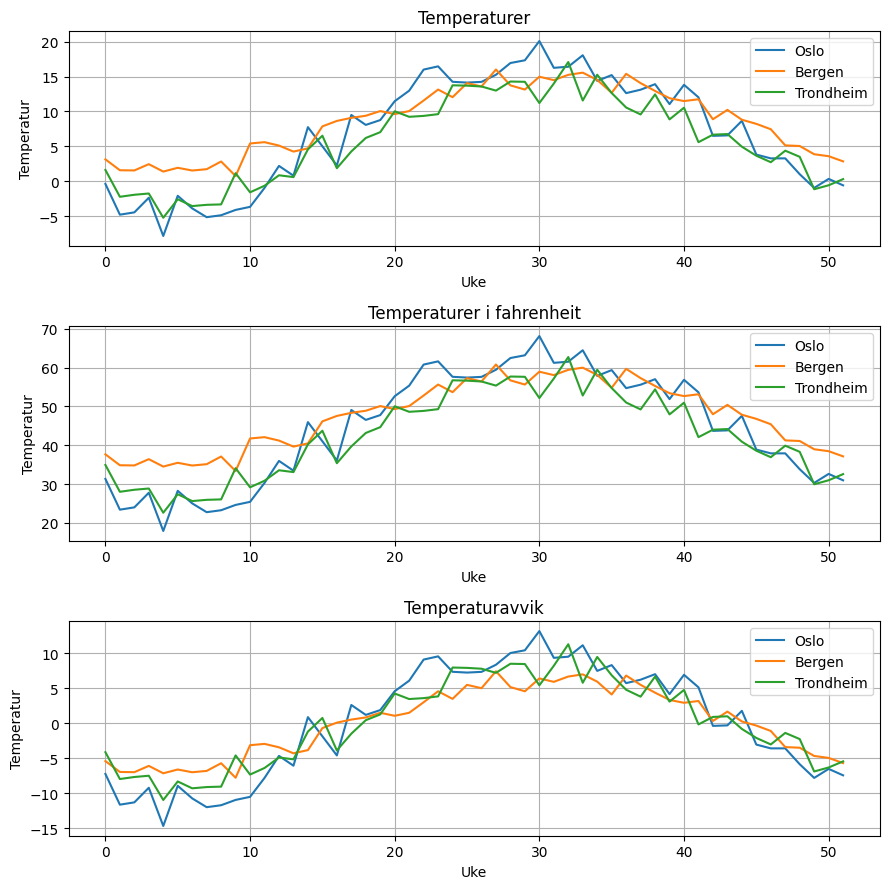

In [74]:
byer = ["Oslo", "Bergen", "Trondheim"]
temperaturer = np.array([[-0.37, -4.77, -4.44, -2.35, -7.82, -2.07, -3.87, -5.13, -4.85, -4.09, -3.65, -0.94,
          2.21, 0.81, 7.76, 5.02, 2.28, 9.5, 8.08, 8.77, 11.47, 12.98, 16.0, 16.46,
          14.25, 14.14, 14.24, 15.26, 16.94, 17.33, 20.08, 16.25, 16.41, 18.05, 14.38, 15.21,
          12.63, 13.12, 13.91, 11.06, 13.82, 12.03, 6.51, 6.58, 8.66, 3.83, 3.29, 3.29,
          1.02, -0.94, 0.35, -0.57], 
          [3.15, 1.59, 1.56, 2.46, 1.4, 1.94, 1.55, 1.74, 2.84, 0.76, 5.42, 5.61,
          5.12, 4.26, 4.72, 7.87, 8.65, 9.09, 9.39, 10.06, 9.63, 10.06, 11.57, 13.14,
          12.05, 14.06, 13.58, 16.01, 13.74, 13.14, 14.98, 14.49, 15.25, 15.56, 14.52, 12.68,
          15.39, 14.06, 12.94, 11.9, 11.49, 11.75, 8.89, 10.23, 8.82, 8.23, 7.46, 5.15,
          5.06, 3.88, 3.6, 2.86], 
          [1.63, -2.21, -1.92, -1.74, -5.21, -2.56, -3.54, -3.36, -3.3, 1.17, -1.57, -0.63,
          0.87, 0.61, 4.58, 6.53, 1.88, 4.28, 6.21, 7.04, 10.03, 9.24, 9.37, 9.62,
          13.75, 13.7, 13.58, 12.99, 14.29, 14.25, 11.21, 14.0, 17.08, 11.57, 15.26, 12.64,
          10.57, 9.58, 12.45, 8.87, 10.54, 5.61, 6.68, 6.77, 4.96, 3.67, 2.74, 4.39,
          3.51, -1.13, -0.56, 0.32]])

main(byer, temperaturer)